<a href="https://colab.research.google.com/github/anacvetkoo/MOS-projekt/blob/main/notebooks/Ziva_teden3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Živa – 3. teden vaj: Stroški študija in zaslužki

**Skupni projekt:** *Ali se študij danes še splača?*  

- **RV3 – Stroški:** šolnine Ivy League, drugih zasebnih neprofitnih in javnih štiriletnih univerz (2004–2023); posebej stroški Ivy League (2009–2023).
- **RV5 – Trg dela:** zaslužki zaposlenih v izbranih računalniških poklicih glede na izobrazbo (ACS 2024). **Zaposlitvene možnosti še niso analizirane.**
- **Povezava z Aninim delom:** RV3 dopolnjuje RV1 (dostopnost) in RV2 (zaključevanje), RV5 pa vsebinsko dopolnjuje RV4 (diplomanti računalništva). CIP 11 in SOC 15-12 ne opisujeta iste populacije.

Priprava podatkov je opisana v `Scorecard_priprava_RV3.ipynb` in `ACS_priprava_IT.ipynb`.

In [1]:
# Priprava okolja in povezava z Google Drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

# Mapa s podatki in mapa za shranjevanje grafov
mapa = Path("/content/drive/MyDrive/FERI/3. letnik/1. semester/MOS/Projekt_teden3")
mapa_grafi = mapa / "grafi"

if not mapa.is_dir():
    raise FileNotFoundError(f"Mapa ni najdena: {mapa}")
mapa_grafi.mkdir(exist_ok=True)

print("Podatkovna mapa:", mapa)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Podatkovna mapa: /content/drive/MyDrive/FERI/3. letnik/1. semester/MOS/Projekt_teden3


## RV3 – Stroški študija

**Vprašanje:** Kako so se spreminjali stroški študija ob upoštevanju inflacije?

- **IPEDS:** `IPEDS_RV3.csv` in `IPEDS_institucije_2004_2024.csv` (pripravila Ana). Šolnine treh skupin univerz, 2004–2023.
- **College Scorecard:** `Scorecard_Ivy_2009_2023.csv` (pripravljeno v pomožnem zvezku). Šolnine, ocenjeni skupni stroški in neto cene Ivy League, 2009–2023.
- **Inflacija:** letno povprečje CPI-U iz FRED. **Realni zneski so izraženi v dolarjih leta 2023.**
- **Metoda:** letne mediane med univerzami; posamezna univerza ima enako težo.

In [2]:
# RV3: Branje podatkov o šolninah in skupinah univerz

df_ipeds = pd.read_csv(
    mapa / "IPEDS_RV3.csv",
    usecols=["UNITID", "leto", "CHG2AY3", "CHG3AY3"]
)
df_ipeds_institucije = pd.read_csv(
    mapa / "IPEDS_institucije_2004_2024.csv",
    usecols=["UNITID", "leto", "SECTOR"]
)

# Identifikatorji osmih univerz Ivy League
ivy_imena = {
    217156: "Brown",
    190150: "Columbia",
    190415: "Cornell",
    182670: "Dartmouth",
    166027: "Harvard",
    186131: "Princeton",
    215062: "UPenn",
    130794: "Yale"
}
ivy_unitid = list(ivy_imena)

print("Zapisi o šolninah:", len(df_ipeds))
print("Obdobje:", df_ipeds["leto"].min(), "–", df_ipeds["leto"].max())

Zapisi o šolninah: 88205
Obdobje: 2004 – 2023


In [3]:
# RV3: Povezovanje podatkov in določitev treh skupin

# Povežem šolnine in vrsto univerze po UNITID in letu
df_rv3_cene = df_ipeds.merge(
    df_ipeds_institucije,
    on=["UNITID", "leto"], how="left", validate="one_to_one"
)
assert df_rv3_cene["SECTOR"].notna().all(), "Manjka oznaka SECTOR."

# SECTOR 1 = javne, 2 = zasebne neprofitne štiriletne univerze
df_rv3_cene = df_rv3_cene[df_rv3_cene["SECTOR"].isin([1, 2])].copy()
df_rv3_cene["Skupina"] = df_rv3_cene["SECTOR"].map({
    1: "Javne štiriletne",
    2: "Druge zasebne neprofitne"
})
df_rv3_cene.loc[df_rv3_cene["UNITID"].isin(ivy_unitid), "Skupina"] = "Ivy League"

# Za javne uporabim in-state šolnino, za zasebne objavljeno šolnino
df_rv3_cene["Solnina_USD"] = np.where(
    df_rv3_cene["SECTOR"] == 1,
    df_rv3_cene["CHG2AY3"],
    df_rv3_cene["CHG3AY3"]
)

# Izločim manjkajoče, ničelne in negativne vrednosti
df_rv3_cene = df_rv3_cene[df_rv3_cene["Solnina_USD"] > 0].copy()

print("Veljavnih zapisov:", len(df_rv3_cene))
print(df_rv3_cene["Skupina"].value_counts())

Veljavnih zapisov: 39916
Skupina
Druge zasebne neprofitne    26144
Javne štiriletne            13612
Ivy League                    160
Name: count, dtype: int64


In [4]:
# RV3: Priprava letnega indeksa inflacije CPI-U

# FRED objavlja mesečni CPI-U; pretvorim ga v letno povprečje
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCNS"
df_cpi = pd.read_csv(url)

# Ime datumskega stolpca je lahko observation_date ali DATE
stolpec_datuma = "observation_date" if "observation_date" in df_cpi.columns else "DATE"
df_cpi["leto"] = pd.to_datetime(df_cpi[stolpec_datuma]).dt.year

df_cpi_letni = df_cpi.groupby("leto", as_index=False)["CPIAUCNS"].mean()
df_cpi_letni = df_cpi_letni[df_cpi_letni["leto"].between(2004, 2023)].copy()
df_cpi_letni = df_cpi_letni.rename(columns={"CPIAUCNS": "CPI"})

assert len(df_cpi_letni) == 20 and df_cpi_letni["CPI"].notna().all(), "Preveri CPI."
cpi_2023 = df_cpi_letni.loc[df_cpi_letni["leto"] == 2023, "CPI"].iloc[0]
print("CPI: 2004–2023; referenčno leto: 2023")

CPI: 2004–2023; referenčno leto: 2023


### 1. Primerjava šolnin treh skupin univerz (2004–2023)

Najprej izračunam **nominalno in realno rast mediane šolnin**. Nato preverim, koliko na primerjavo vpliva to, da nabor univerz skozi čas ni enak.

In [5]:
# RV3: Mediane šolnin in rast po skupinah

# Mediana šolnin in število univerz za vsako leto
df_rv3_trend = df_rv3_cene.groupby(["leto", "Skupina"]).agg(
    mediana_solnine=("Solnina_USD", "median"),
    stevilo_univerz=("UNITID", "nunique")
).reset_index()

# Upoštevanje inflacije
df_rv3_trend = df_rv3_trend.merge(df_cpi_letni, on="leto", validate="many_to_one")
# Preračun nominalne šolnine v dolarje z vrednostjo leta 2023
df_rv3_trend["realna_solnina"] = (
    df_rv3_trend["mediana_solnine"] * cpi_2023 / df_rv3_trend["CPI"]
)

# Primerjam začetno in končno leto
pregled_rv3 = df_rv3_trend[df_rv3_trend["leto"].isin([2004, 2023])].pivot(
    index="Skupina", columns="leto",
    values=["mediana_solnine", "realna_solnina", "stevilo_univerz"]
)
pregled_rv3.columns = [
    "Nominalno_2004", "Nominalno_2023", "Realno_2004", "Realno_2023",
    "Univerze_2004", "Univerze_2023"
]

# Izračun nominalne in realne (vrednosti prilagojene za inflacijo) rasti
pregled_rv3["Nominalna_rast_pct"] = (
    (pregled_rv3["Nominalno_2023"] / pregled_rv3["Nominalno_2004"] - 1) * 100
).round(1)
pregled_rv3["Realna_rast_pct"] = (
    (pregled_rv3["Realno_2023"] / pregled_rv3["Realno_2004"] - 1) * 100
).round(1)

display(pregled_rv3[["Univerze_2004", "Univerze_2023", "Nominalna_rast_pct", "Realna_rast_pct"]])

# Kontrola: vseh osem univerz Ivy League mora biti prisotnih v vseh letih
ivy = df_rv3_trend[df_rv3_trend["Skupina"] == "Ivy League"]
assert len(ivy) == 20 and (ivy["stevilo_univerz"] == 8).all()

,Univerze_2004,Univerze_2023,Nominalna_rast_pct,Realna_rast_pct
Skupina,,,,
Druge zasebne neprofitne,1276.0,1309.0,98.2,22.8
Ivy League,8.0,8.0,115.7,33.7
Javne štiriletne,596.0,777.0,90.6,18.1


**Kaj pokaže osnovna primerjava?**

- Realna rast šolnin med letoma 2004 in 2023: **Ivy League +33,7 %**, druge zasebne neprofitne **+22,8 %**, javne štiriletne **+18,1 %**.
- Nominalna rast je bila višja v vseh treh skupinah; šolnine so torej zrasle tudi po upoštevanju inflacije.
- **Pozor:** število univerz se skozi čas spreminja. Razlike v rasti lahko odražajo tudi spremembo sestave skupin.

In [6]:
# RV3: Dodatno preverjanje – isti nabor univerz v letih 2004 in 2023

# Obdržim samo začetno in končno leto
krajni_leti = df_rv3_cene[df_rv3_cene["leto"].isin([2004, 2023])].copy()

# Poiščem univerze, ki so v isti skupini prisotne v obeh letih
isti_nabor = krajni_leti.groupby(["UNITID", "Skupina"])["leto"].nunique()
isti_nabor = isti_nabor[isti_nabor == 2].index
krajni_leti = krajni_leti.set_index(["UNITID", "Skupina"]).loc[isti_nabor].reset_index()

# Izračunam mediane
rast_stalni = krajni_leti.groupby(["Skupina", "leto"])["Solnina_USD"].median().unstack()  # .unstack() preoblikuje tabelo, da sta 2004 in 2023 v ločenih stolpcih
rast_stalni["Univerze"] = krajni_leti.groupby("Skupina")["UNITID"].nunique() # koliko univerz je v vsaki skupini

# Ponovno izračunam realno rast, tokrat samo za stalni nabor univerz
cpi_2004 = df_cpi_letni.loc[df_cpi_letni["leto"] == 2004, "CPI"].iloc[0]
rast_stalni["Realna_rast_pct"] = (
    (rast_stalni[2023] / rast_stalni[2004]) * (cpi_2004 / cpi_2023) - 1
) * 100

display(rast_stalni[["Univerze", "Realna_rast_pct"]].round(1))

leto,Univerze,Realna_rast_pct
Skupina,,
Druge zasebne neprofitne,1069,31.3
Ivy League,8,33.7
Javne štiriletne,565,32.5


**Kaj pove preverjanje istega nabora?**

- Med istimi univerzami v letih **2004 in 2023** je realna rast znašala: **Ivy League +33,7 % (8)**, druge zasebne neprofitne **+31,3 % (1.069)** in javne štiriletne **+32,5 % (565)**.
- Razlike med skupinami so **veliko manjše** kot pri prvotni primerjavi vseh razpoložljivih univerz.
- **Sklep:** Ivy League ima v tej preverbi le nekoliko višjo rast; trditev, da se je podražila bistveno hitreje, ni dovolj trdna.
- **Pomen »isti nabor«:** gre za univerze z veljavno šolnino v **obeh končnih letih**, ne nujno za univerze z neprekinjenimi podatki v vseh 20 letih.

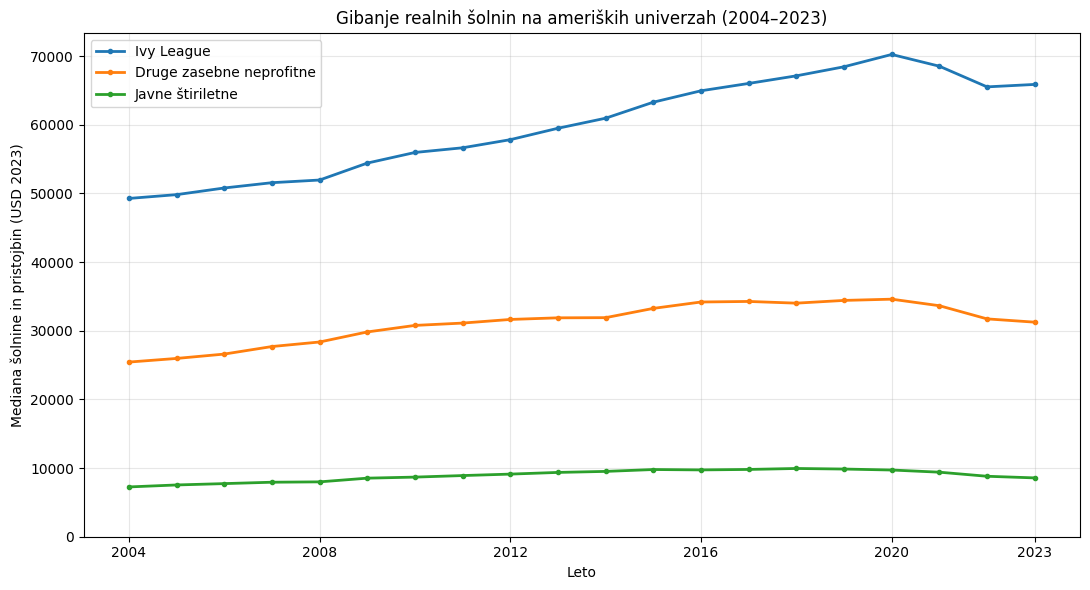

In [7]:
# RV3: Graf realnih šolnin treh skupin univerz

plt.figure(figsize=(11, 6))

skupine = ["Ivy League", "Druge zasebne neprofitne", "Javne štiriletne"]
for skupina in skupine:
    podatki = df_rv3_trend[df_rv3_trend["Skupina"] == skupina]
    plt.plot(
        podatki["leto"], podatki["realna_solnina"],
        marker="o", markersize=3, linewidth=2, label=skupina
    )

plt.title("Gibanje realnih šolnin na ameriških univerzah (2004–2023)")
plt.xlabel("Leto")
plt.ylabel("Mediana šolnine in pristojbin (USD 2023)")
plt.xticks([2004, 2008, 2012, 2016, 2020, 2023])
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Shranim realni graf v Google Drive
plt.savefig(mapa_grafi / "RV3_trend_skupine_2004_2023_realno.png", dpi=300)
plt.show()

**Interpretacija grafa:**

- Prikazuje **mediane šolnin v dolarjih leta 2023** – inflacija je že upoštevana.
- Ivy League ima skozi obdobje bistveno **višjo raven šolnin**; to pa še ne pomeni bistveno **hitrejše odstotne rasti**.
- Graf za vsako leto vključuje vse univerze z veljavnimi podatki. Razlika v rasti med skupinami je zato občutljiva na sestavo vzorca (glej preverbo zgoraj).

### 2. Šolnine, skupni stroški in neto cene Ivy League (2009–2023)

V tem delu analiziram gibanje treh kazalnikov stroškov študija na univerzah Ivy League:

- **Šolnina (`Solnina_USD`):** objavljena letna šolnina in obvezne pristojbine, brez večine dodatnih življenjskih stroškov.
- **Skupni stroški (`COSTT4_A`):** ocenjeni letni stroški študija, ki poleg šolnine vključujejo tudi bivanje, prehrano in druge izdatke.
- **Neto cena (`NPT4_PRIV`):** povprečni stroški po odšteti nepovratni finančni pomoči za redne, prvič vpisane študente, ki prejemajo zvezno finančno pomoč (Title IV).

**Namen analize:** preveriti, kako so se spreminjali objavljeni stroški študija in neto cene po upoštevanju finančne pomoči.

**Pomembno:** Neto cena velja samo za določeno skupino študentov in ne predstavlja povprečnega stroška vseh študentov Ivy League.

In [8]:
# RV3: Povezovanje stroškov Ivy League (College Scorecard + IPEDS)

# College Scorecard: neto cena in ocenjeni skupni stroški
df_neto_ivy = pd.read_csv(
    mapa / "Scorecard_Ivy_2009_2023.csv",
    usecols=["UNITID", "leto", "NPT4_PRIV", "COSTT4_A"]
)

# IPEDS: šolnina istih univerz
df_ivy_solnine = df_rv3_cene[
    df_rv3_cene["Skupina"] == "Ivy League"
][["UNITID", "leto", "Solnina_USD"]]

# Povežem po univerzi in letu
df_ivy_stroski = df_neto_ivy.merge(
    df_ivy_solnine, on=["UNITID", "leto"], validate="one_to_one"
)

# Preverim 8 univerz × 15 let in popolnost podatkov
assert len(df_ivy_stroski) == 120 and df_ivy_stroski.notna().all().all(), "Preveri podatke Ivy League."
print("Povezanih zapisov:", len(df_ivy_stroski), "(8 univerz × 15 let)")

Povezanih zapisov: 120 (8 univerz × 15 let)


In [9]:
# RV3: Letne mediane treh stroškovnih kazalnikov in rast

kazalniki = {
    "Šolnina": "Solnina_USD",
    "Skupni stroški": "COSTT4_A",
    "Neto cena": "NPT4_PRIV"
}

# Mediane osmimh univerz za vsako leto
df_ivy_trend = df_ivy_stroski.groupby(
    "leto", as_index=False
)[list(kazalniki.values())].median()

# Dodam podatke o inflaciji
df_ivy_trend = df_ivy_trend.merge(df_cpi_letni, on="leto", validate="one_to_one")

# Vsak kazalnik preračunam v USD leta 2023 (realne mediane)
for stolpec in kazalniki.values():
    df_ivy_trend[stolpec + "_realno"] = (
        df_ivy_trend[stolpec] * cpi_2023 / df_ivy_trend["CPI"]
    )

# Izberem mediane za leti 2009 in 2023 za izračun rasti
prvo = df_ivy_trend[df_ivy_trend["leto"] == 2009].iloc[0]
zadnje = df_ivy_trend[df_ivy_trend["leto"] == 2023].iloc[0]

pregled_ivy = pd.DataFrame([
    {
        "Kazalnik": ime,
        "Nominalna rast (%)": round((zadnje[s] / prvo[s] - 1) * 100, 1),
        "Realna rast (%)": round((zadnje[s + "_realno"] / prvo[s + "_realno"] - 1) * 100, 1)
    }
    for ime, s in kazalniki.items()
])
display(pregled_ivy)

,Kazalnik,Nominalna rast (%),Realna rast (%)
0,Šolnina,71.9,21.1
1,Skupni stroški,66.9,17.5
2,Neto cena,60.0,12.7


**Kaj kaže primerjava 2009–2023?**

- Objavljena šolnina Ivy League je realno zrasla za **21,1 %**, ocenjeni skupni stroški za **17,5 %**.
- Neto cena je realno zrasla za **12,7 %**, **če izberemo leto 2009 kot izhodišče**.
- To je primerjava dveh let, ne dokaz enakomerne rasti skozi celotno obdobje. Zato posebej preverim druga začetna leta.

In [10]:
# RV3: Kako izbira začetnega leta vpliva na rast realnih neto cen?

neto = df_ivy_trend.set_index("leto")["NPT4_PRIV_realno"]
rezultati = []

for leto in [2009, 2010, 2011, 2012]:
    rast = (neto.loc[2023] / neto.loc[leto] - 1) * 100
    rezultati.append({
        "Začetno leto": leto,
        "Realna rast do 2023 (%)": round(rast, 1)
    })

display(pd.DataFrame(rezultati))

,Začetno leto,Realna rast do 2023 (%)
0,2009,12.7
1,2010,27.5
2,2011,-5.5
3,2012,-6.6


**Ugotovitve – vpliv izbire začetnega leta na neto cene**

- Preverila sem, kako se realna rast neto cen spremeni, če izberem različna začetna leta.
- Od leta **2009 do 2023** so se neto cene realno povečale za **12,7 %**, od leta **2010 za 27,5 %**, od let **2011 in 2012** pa so se celo zmanjšale.
- Ugotovila sem, da so **neto cene skozi obdobje precej nihale**, zato je zaključek o njihovi rasti odvisen od izbire začetnega leta.
- Iz teh podatkov ne morem zanesljivo sklepati, kaj je povzročilo nihanja.

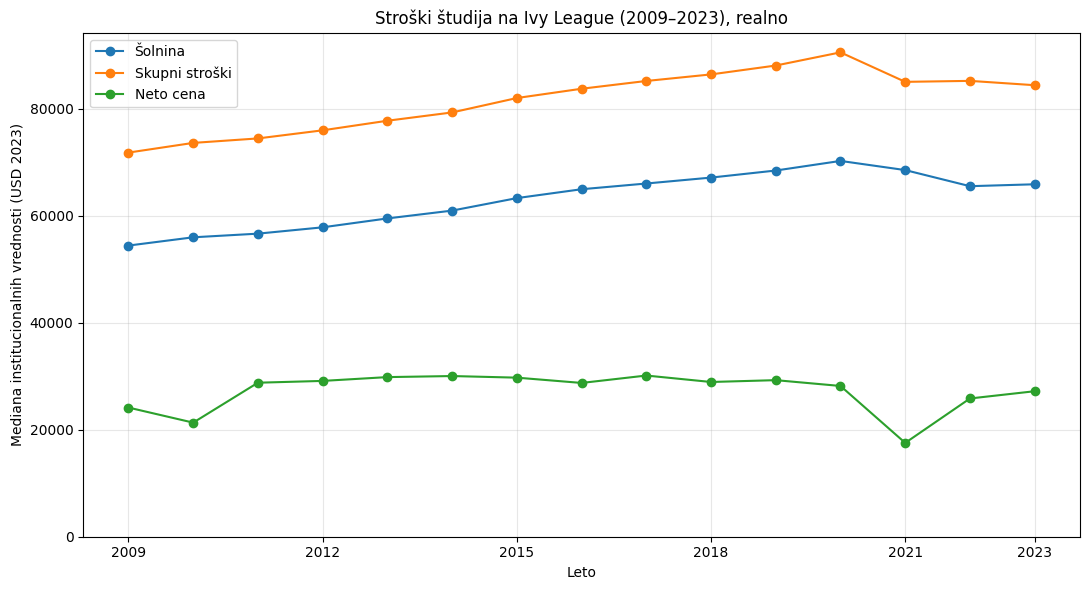

In [11]:
# RV3: Graf realnih stroškov Ivy League

plt.figure(figsize=(11, 6))

# Trije kazalniki – že prilagojeni za inflacijo
plt.plot(df_ivy_trend["leto"], df_ivy_trend["Solnina_USD_realno"],
         marker="o", label="Šolnina")
plt.plot(df_ivy_trend["leto"], df_ivy_trend["COSTT4_A_realno"],
         marker="o", label="Skupni stroški")
plt.plot(df_ivy_trend["leto"], df_ivy_trend["NPT4_PRIV_realno"],
         marker="o", label="Neto cena")

plt.title("Stroški študija na Ivy League (2009–2023), realno")
plt.xlabel("Leto")
plt.ylabel("Mediana institucionalnih vrednosti (USD 2023)")
plt.xticks([2009, 2012, 2015, 2018, 2021, 2023])
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(mapa_grafi / "RV3_ivy_stroski_neto_2009_2023_realno.png", dpi=300)
plt.show()

**Interpretacija grafa:**

- **Šolnine in skupni stroški** so se ob upoštevanju inflacije večinoma povečevali do leta 2020, nato pa nekoliko znižali. Leta 2023 so bili še vedno višji kot leta 2009.
- **Neto cene so precej bolj nihale.** Posebej izstopa velik padec leta 2021, vendar iz podatkov ne morem zanesljivo ugotoviti, kaj ga je povzročilo.
- **Neto cene so bistveno nižje od objavljenih skupnih stroškov**, kar kaže na pomembno vlogo finančne pomoči za obravnavano skupino študentov.
- **Ugotovitev:** Pri ocenjevanju finančne dostopnosti Ivy League ni dovolj gledati samo objavljenih šolnin, ampak je treba upoštevati tudi skupne stroške in finančno pomoč.

### Metodološke omejitve RV3

- **Podatki in leta:** IPEDS in College Scorecard nimata nujno povsem usklajenih akademskih let, zato posameznih nihanj ne razlagam brez dodatnih dokazov.
- **Neto cena:** Velja samo za določeno skupino študentov s finančno pomočjo Title IV, ne za vse študente Ivy League.
- **Primerjava univerz:** Uporabljam mediane univerz, ne povprečnih stroškov študentov. Pri javnih univerzah upoštevam *in-state* šolnine.
- **Spremembe vzorca:** Nabor univerz se skozi leta spreminja, zato sem preverila tudi rast na istem naboru univerz v začetnem in končnem letu.
- **Inflacija:** Stroške preračunam z indeksom CPI v dolarje leta 2023.
- **Obdobje:** Šolnine primerjam za 2004–2023, stroške in neto cene Ivy League pa za 2009–2023, zato rasti med obdobjema niso neposredno primerljive.

---

## RV5 – Zaslužki v izbranih računalniških poklicih glede na izobrazbo

**Vprašanje:** Kako se zaslužki in zaposlitvene možnosti v IT razlikujejo glede na izobrazbo?

**V tem tednu analiziram samo zaslužke**, ne zaposlitvenih možnosti.

- **Vir:** IPUMS ACS 2024, pripravljena datoteka `ACS_2019_2022_2024_IT.csv` iz `ACS_priprava_IT.ipynb`.
- **Poklici:** izbrani računalniški poklici SOC 15-12, ne celotni IT-sektor.
- **Osebe:** zaposleni v ZDA, stari 25–64 let, s pozitivnim letnim zaslužkom iz zaposlitve.
- **Primerjava:** srednja šola/GED, bachelor's degree, master's degree.
- **Metoda:** utežena mediana zaslužka z `PERWT`. Povezave niso dokaz vzročnosti.

**Izbor obdobja:**

- Za primerjavo zaslužkov glede na izobrazbo uporabim podatke ACS za **leto 2024**, ki je najnovejše izbrano leto.
- Primerjam zaposlene v izbranih računalniških poklicih, stare **25–64 let**.
- Analiza prikazuje **razlike med izobrazbenimi skupinami v letu 2024**, ne sprememb zaslužkov skozi čas.

In [12]:
# RV5: Preberem podatke in izberem leto 2024

df_acs_it = pd.read_csv(
    mapa / "ACS_2019_2022_2024_IT.csv",
    usecols=["YEAR", "AGE", "EDUCD", "EMPSTAT", "INCWAGE", "PERWT"]
)
df_acs_it_2024 = df_acs_it[df_acs_it["YEAR"] == 2024].copy()

print("Zapisov iz računalniških poklicev v 2024:", len(df_acs_it_2024))

Zapisov iz računalniških poklicev v 2024: 65474


In [13]:
# RV5: Izberem zaposlene in tri izobrazbene skupine

izobrazba_kode = {
    63: "Srednja šola / GED", 64: "Srednja šola / GED",
    101: "Bachelor's degree", 114: "Master's degree"
}

# pogoji - upoštevam starost, zaposlenost, veljaven zaslužek in pozitivno utež
maska = (
    df_acs_it_2024["AGE"].between(25, 64)
    & (df_acs_it_2024["EMPSTAT"] == 1)
    & (df_acs_it_2024["INCWAGE"] > 0)
    & (~df_acs_it_2024["INCWAGE"].isin([999998, 999999]))
    & (df_acs_it_2024["PERWT"] > 0)
    & (df_acs_it_2024["EDUCD"].isin(izobrazba_kode))
)

# Izberem ustrezne osebe glede na pogoje
df_rv5 = df_acs_it_2024.loc[maska].copy()

df_rv5["Izobrazba"] = df_rv5["EDUCD"].map(izobrazba_kode)
vrstni_red = ["Srednja šola / GED", "Bachelor's degree", "Master's degree"]

print("Zapisi po izobrazbi:")
print(df_rv5["Izobrazba"].value_counts().reindex(vrstni_red))
print("Skupaj:", len(df_rv5))

Zapisi po izobrazbi:
Izobrazba
Srednja šola / GED     2563
Bachelor's degree     23398
Master's degree       11401
Name: count, dtype: int64
Skupaj: 37362


In [14]:
# RV5: Utežene mediane letnih zaslužkov
# utežena - upošteva koliko ljudi v populaciji predstavlja posamezna oseba v vzorcu (PERWT)

def utezena_mediana(vrednosti, utezi):
    indeksi = np.argsort(vrednosti)
    zneski = np.asarray(vrednosti)[indeksi]        # Razvrsti zaslužke (vrednosti) od najnižjega do najvišjega
    utezi_urejeno = np.asarray(utezi)[indeksi]     # Uteži v istem vrstnem redu
    polovica = utezi_urejeno.sum() / 2             # Polovica vsote uteži
    return zneski[np.searchsorted(np.cumsum(utezi_urejeno), polovica)]  # Utežena mediana

# Izračun za vsako izobrazbeno skupino
rezultati = []
for skupina in vrstni_red:
    podatki = df_rv5[df_rv5["Izobrazba"] == skupina]
    rezultati.append({
        "Izobrazba": skupina,
        "Stevilo_oseb": len(podatki),
        "Mediana_USD": utezena_mediana(podatki["INCWAGE"], podatki["PERWT"])
    })

df_median = pd.DataFrame(rezultati)
display(df_median)

,Izobrazba,Stevilo_oseb,Mediana_USD
0,Srednja šola / GED,2563,71000
1,Bachelor's degree,23398,107000
2,Master's degree,11401,130000


**Kaj pove preglednica?**

- Analiziranih je **37.362 vzorčnih zapisov**.
- Utežene mediane letnih zaslužkov: **71.000 USD** (srednja šola/GED), **107.000 USD** (bachelor's), **130.000 USD** (master's).
- **Ugotovitev:** Višja izobrazba je povezana z višjimi letnimi zaslužki v izbranih računalniških poklicih.
- **Omejitev:** Analiziram že zaposlene, ne začetnih plač ali verjetnosti zaposlitve. Razlike v zaslužkih niso nujno posledica samo izobrazbe.

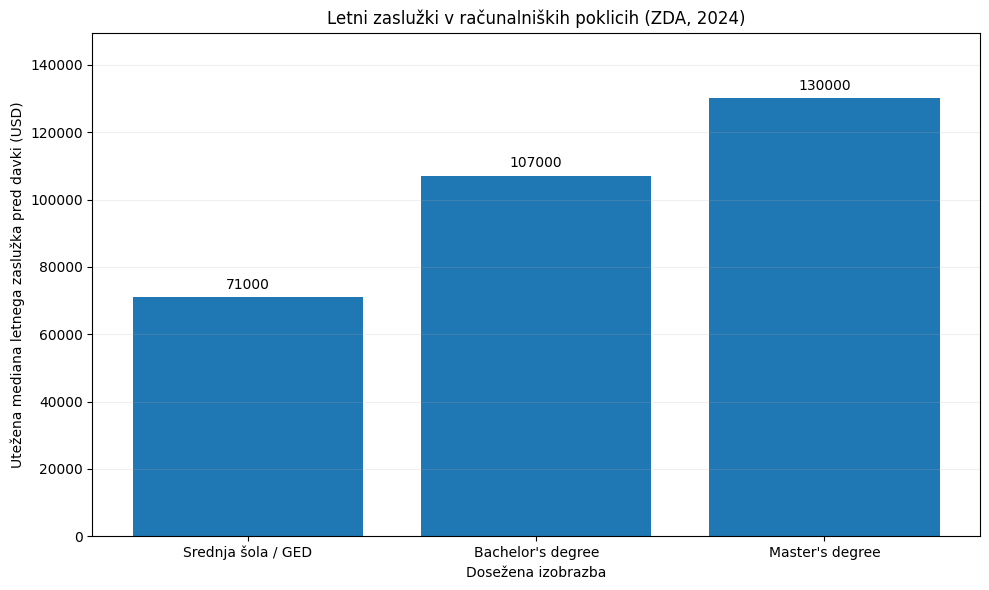

In [15]:
# RV5: Stolpčni graf uteženih median zaslužkov

plt.figure(figsize=(10, 6))
stolpci = plt.bar(df_median["Izobrazba"], df_median["Mediana_USD"])
plt.bar_label(stolpci, fmt="%.0f", padding=4)  # Zneski nad stolpci

plt.title("Letni zaslužki v računalniških poklicih (ZDA, 2024)")
plt.xlabel("Dosežena izobrazba")
plt.ylabel("Utežena mediana letnega zaslužka pred davki (USD)")
plt.ylim(0, df_median["Mediana_USD"].max() * 1.15)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(mapa_grafi / "RV5_it_zasluzki_izobrazba_2024.png", dpi=300)
plt.show()

### Ugotovitve in omejitve RV5

- **Ugotovitev:** v izbranih računalniških poklicih imajo zaposleni z višjo izobrazbo višje mediane letnih zaslužkov. To je **opisna povezava, ne dokaz**, da je razlike povzročila izobrazba.
- **Primerljivost skupin:** analiza ne ločuje polnega in krajšega delovnega časa; vplivajo lahko tudi starost, izkušnje, vrsta poklica in druge okoliščine.
- **Pomen podatkov:** `INCWAGE` meri bruto zaslužke iz zaposlitve v zadnjih 12 mesecih, ne začetnih plač; `PERWT` so vzorčne uteži.
- **Obseg:** vključene so tri izobrazbene skupine in SOC 15-12, **ne celoten IT-sektor**. Ta poklicna skupina ni enaka Anini študijski klasifikaciji CIP 11.
- **Kaj še manjka pri RV5:** zaposlitvene možnosti niso ocenjene; trenutni filtrirani podatki o osebah v računalniških poklicih niso ustrezna osnova za oceno verjetnosti vstopa v IT.

**Vir:** IPUMS USA – ACS 2024. Opisna primerjava zaslužkov zaposlenih v izbranih računalniških poklicih.